In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.collections import LineCollection

In [2]:
# Data
with np.load("starry_wind.npz") as data:

    segments = data["segments"]
    values = data["values"]

    lon = data["lon"]
    lat = data["lat"]

    u = data["u"]
    v = data["v"]
    speed = data["speed"]

    extent = data["extent"]

In [3]:
# Wind speed colors
colors = [
    "#17264F",
    "#244A85",
    "#397CB4",
    "#5FA6C7",
    "#A7C8C3",
    "#F2D779",
    "#F7C34B"
]

cmap = mcolors.LinearSegmentedColormap.from_list("starry_wind", colors)
norm = mcolors.Normalize(vmin=0, vmax=np.nanpercentile(speed, 98))

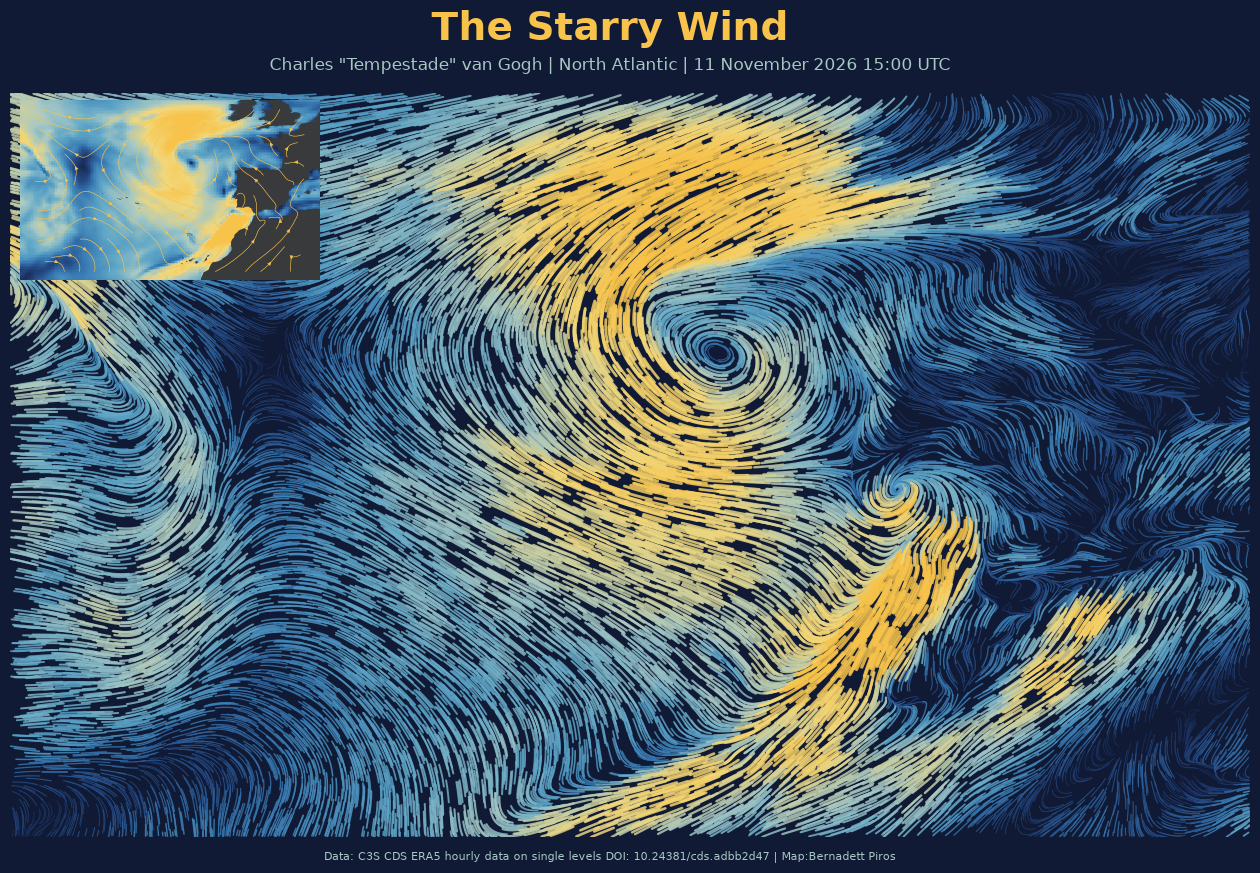

In [4]:
fig, ax = plt.subplots( figsize=(16, 10), facecolor="#101A35")

strokes = LineCollection(segments, array=values, cmap=cmap, norm=norm,
                         linewidths=0.4 + 1.8 * norm(values), alpha=0.85, capstyle="round")

ax.add_collection(strokes)

ax.set_xlim(extent[:2])
ax.set_ylim(extent[2:])

ax.set_aspect("equal")
ax.set_facecolor("#101A35")
ax.set_axis_off()

# Inset
inset_ax = fig.add_axes([0.125, 0.68, 0.2, 0.18], projection=ccrs.PlateCarree())  

# Wind speed
inset_ax.pcolormesh(lon, lat, speed, cmap=cmap, norm=norm)

# Land 
inset_ax.add_feature(cfeature.LAND, facecolor="#393A3C", ec="none", zorder=1)

# Wind vectors
inset_ax.streamplot(lon, lat, u, v, color="#F7C34B", density=0.7, linewidth=0.45, arrowsize=0.5)  

inset_ax.set_extent(extent, crs=ccrs.PlateCarree())
inset_ax.spines["geo"].set_visible(False)
inset_ax.set_facecolor("#101A35")

# Title
fig.text(0.5, 0.95,
             "The Starry Wind",
             color="#F7C34B", size=28, weight="bold", ha="center", va="top")

# Subtitle
fig.text(0.5, 0.89,
         f'Charles "Tempestade" van Gogh | North Atlantic | 11 November 2026 15:00 UTC',
         color="#A7C8C3", size=12,  ha="center")   

# Caption
fig.text(0.5, 0.1,
         "Data: C3S CDS ERA5 hourly data on single levels DOI: 10.24381/cds.adbb2d47 | Map:Bernadett Piros",
         color="#A7C8C3", size=8, ha="center")

plt.show()

#fig.savefig("charles.png", bbox_inches="tight", pad_inches=0.2)